## **Đề bài: Tìm các trường đại học có đặc điểm tương đồng bằng KD-Tree**

In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('votes_skills_anon.csv')
df.head()

,index,SUID,univid,response
0,0,538.0,5c9e7a6834cda4f3677e662b,Internationality
1,1,2285.0,5c9e373c34cda4f3677e14ef,Practical relevance / professionalization
2,2,2285.0,5c9e7d8334cda4f3677e6b4f,Internationality
3,3,2285.0,5e84b8a01ead1a77be3bd3a8,Soft skills and digital literacy
4,4,2285.0,5c9e471734cda4f3677e2ed7,Internationality


In [39]:
print(set(df['response'].tolist()))

{'Soft skills and digital literacy', 'Academic excellence', 'Specialization', 'Practical relevance / professionalization', 'Internationality'}


In [40]:
print("-------- Check Data Types --------")
print(df.info())
print("\n-------- Check Null Values --------")
print(df.isnull().sum())

-------- Check Data Types --------
<class 'pandas.DataFrame'>
RangeIndex: 23239 entries, 0 to 23238
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   index     23239 non-null  int64  
 1   SUID      23239 non-null  float64
 2   univid    23239 non-null  str    
 3   response  23239 non-null  str    
dtypes: float64(1), int64(1), str(2)
memory usage: 726.3 KB
None

-------- Check Null Values --------
index       0
SUID        0
univid      0
response    0
dtype: int64


In [41]:
skills = (
    df.value_counts(["univid", "response"])
      .reset_index(name="value")
)
skills.head(10)

,univid,response,value
0,5c9e4dfb34cda4f3677e3a15,Internationality,157
1,5c9e49df34cda4f3677e3365,Academic excellence,156
2,5c9e70bd34cda4f3677e621f,Soft skills and digital literacy,129
3,5c9e61c234cda4f3677e4d7b,Academic excellence,123
4,5c9e498a34cda4f3677e32d9,Internationality,116
5,5c9e677634cda4f3677e5643,Internationality,112
6,5c9e70bd34cda4f3677e621f,Internationality,112
7,5e84a9f41ead1a77be3bd385,Internationality,100
8,5c9e49df34cda4f3677e3365,Internationality,96
9,5c9e636734cda4f3677e5027,Academic excellence,96


In [42]:
skills_wide = skills.pivot(
    index="univid",
    columns="response",
    values="value"
)

skills_wide.head(10)

response,Academic excellence,Internationality,Practical relevance / professionalization,Soft skills and digital literacy,Specialization
univid,,,,,
5c9e345f34cda4f3677e1047,10.0,24.0,10.0,7.0,18.0
5c9e349434cda4f3677e109f,5.0,10.0,12.0,9.0,15.0
5c9e34a834cda4f3677e10bd,8.0,10.0,8.0,6.0,8.0
5c9e34ae34cda4f3677e10c7,1.0,17.0,17.0,14.0,17.0
5c9e34d534cda4f3677e1107,10.0,11.0,15.0,10.0,24.0
5c9e34f634cda4f3677e113b,13.0,48.0,22.0,24.0,32.0
5c9e355234cda4f3677e11d1,8.0,10.0,10.0,9.0,8.0
5c9e355634cda4f3677e11d7,13.0,27.0,23.0,22.0,28.0
5c9e355834cda4f3677e11d9,11.0,25.0,28.0,26.0,23.0


In [ ]:
skills_wide = skills_wide.fillna(0)

# Chuẩn hóa: chia mỗi hàng cho tổng của hàng đó
X_train = skills_wide.div(skills_wide.sum(axis=1), axis=0)
X_train.head()

response,Academic excellence,Internationality,Practical relevance / professionalization,Soft skills and digital literacy,Specialization
univid,,,,,
5c9e345f34cda4f3677e1047,0.144928,0.347826,0.144928,0.101449,0.260870
5c9e349434cda4f3677e109f,0.098039,0.196078,0.235294,0.176471,0.294118
5c9e34a834cda4f3677e10bd,0.200000,0.250000,0.200000,0.150000,0.200000
5c9e34ae34cda4f3677e10c7,0.015152,0.257576,0.257576,0.212121,0.257576
5c9e34d534cda4f3677e1107,0.142857,0.157143,0.214286,0.142857,0.342857


In [ ]:
from sklearn.neighbors import KDTree

kdtree = KDTree(X_train.values)

In [ ]:
def find_similar_universities(target_univid, k=5):
    if target_univid not in X_train.index:
        print(f"Không tìm thấy trường có univid: {target_univid}")
        return None
    
    target_idx = X_train.index.get_loc(target_univid)
    target_vector = X_train.iloc[target_idx].values.reshape(1, -1)
    
    distances, indices = kdtree.query(target_vector, k=k + 1)
    
    neighbor_indices = indices[0][1:]
    neighbor_distances = distances[0][1:]
    
    similar_ids = X_train.index[neighbor_indices]
    result = X_train.loc[similar_ids].copy()
    result.insert(0, "distance", neighbor_distances)
    
    print(f"--- {k} trường tương đồng nhất với trường {target_univid} ---")
    return result

In [ ]:
sample_univid = X_train.index[0]
similar_df = find_similar_universities(sample_univid, k=5)
similar_df

--- 5 trường tương đồng nhất với trường 5c9e345f34cda4f3677e1047 ---


response,distance,Academic excellence,Internationality,Practical relevance / professionalization,Soft skills and digital literacy,Specialization
univid,,,,,,
5c9e519734cda4f3677e4003,0.024258,0.159091,0.340909,0.136364,0.113636,0.250000
5c9e3c6a34cda4f3677e1d67,0.043176,0.157895,0.342105,0.131579,0.131579,0.236842
5c9e895334cda4f3677e7141,0.048605,0.126126,0.333333,0.180180,0.117117,0.243243
5c9e5bfe34cda4f3677e4403,0.058593,0.159091,0.295455,0.159091,0.113636,0.272727
5c9e8c6334cda4f3677e7457,0.072489,0.200000,0.320000,0.120000,0.080000,0.280000


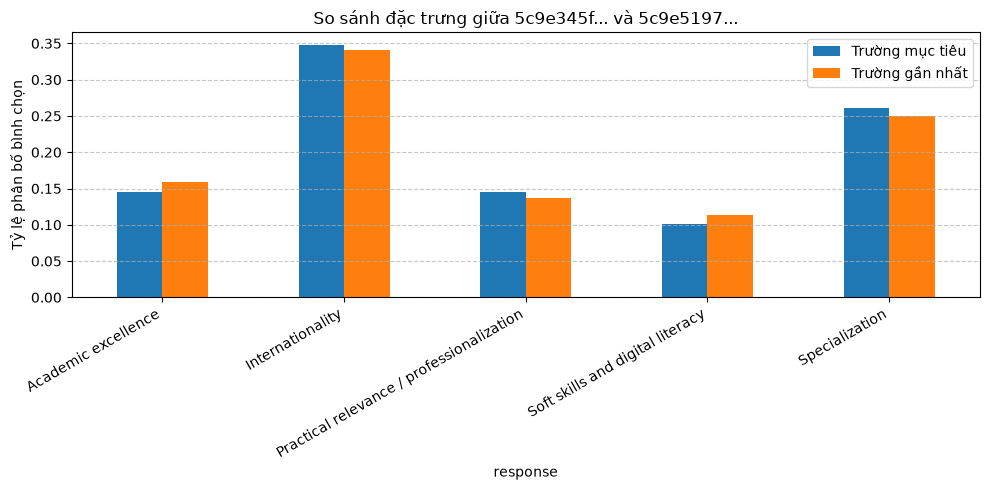

In [ ]:
target_features = X_train.loc[sample_univid]
most_similar_id = similar_df.index[0]
most_similar_features = X_train.loc[most_similar_id]

comparison_df = pd.DataFrame({
    "Trường mục tiêu": target_features,
    "Trường gần nhất": most_similar_features
})

comparison_df.plot(kind="bar", figsize=(10, 5))
plt.title(f"So sánh đặc trưng giữa {sample_univid[:8]}... và {most_similar_id[:8]}...")
plt.ylabel("Tỷ lệ phân bố bình chọn")
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()